In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import scipy.stats as stats # for qq plot

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score

from sklearn.preprocessing import PowerTransformer

In [6]:
df = pd.read_csv('concrete_data.csv')

In [7]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [8]:
df.shape

(1030, 9)

In [11]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [12]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [13]:
X = df.drop(columns=['Strength'])
y = df.iloc[:,-1]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
# applying Regression without any transformation

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

r2_score(y_test, y_pred)

0.6275531792314851

In [21]:
# cross checking with cross value score

lr = LinearRegression()
np.mean(cross_val_score(lr, X, y, scoring='r2'))
# this gives even worse o/p fro this case

np.float64(0.4609940491662865)

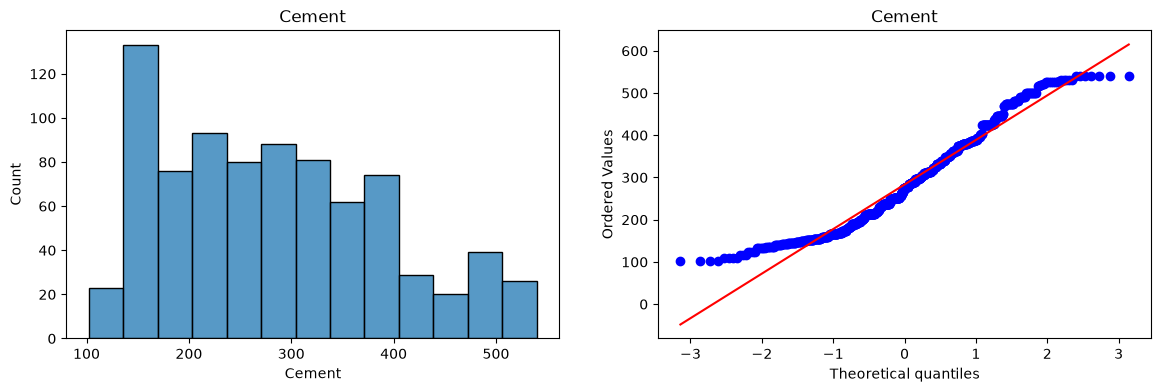

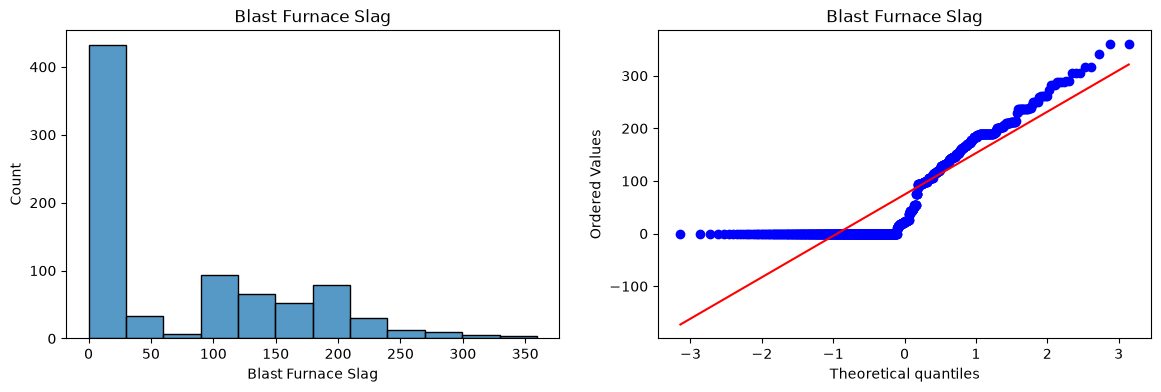

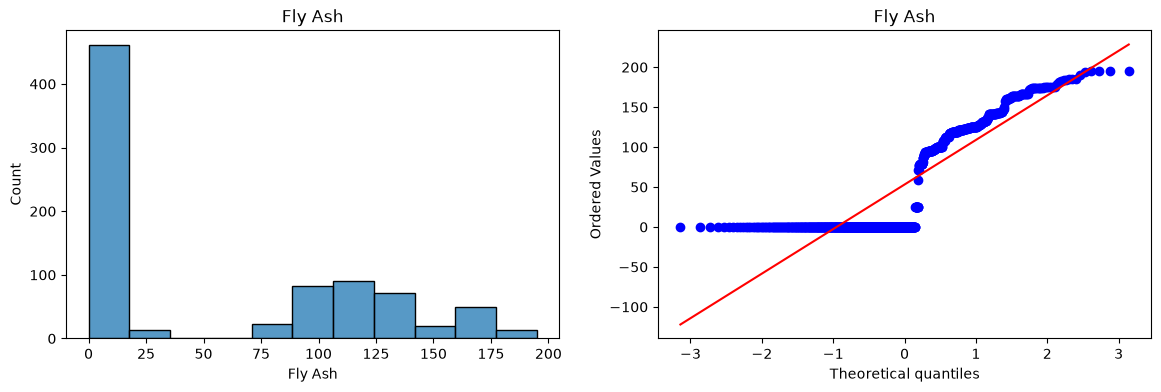

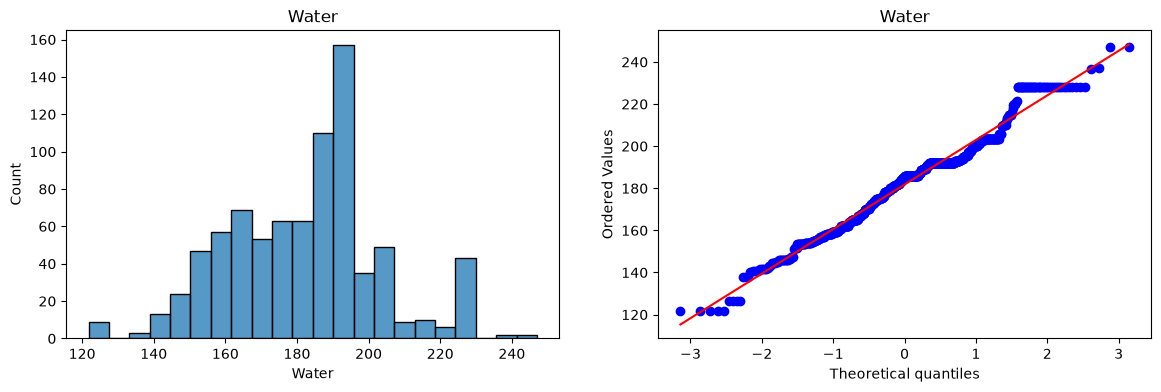

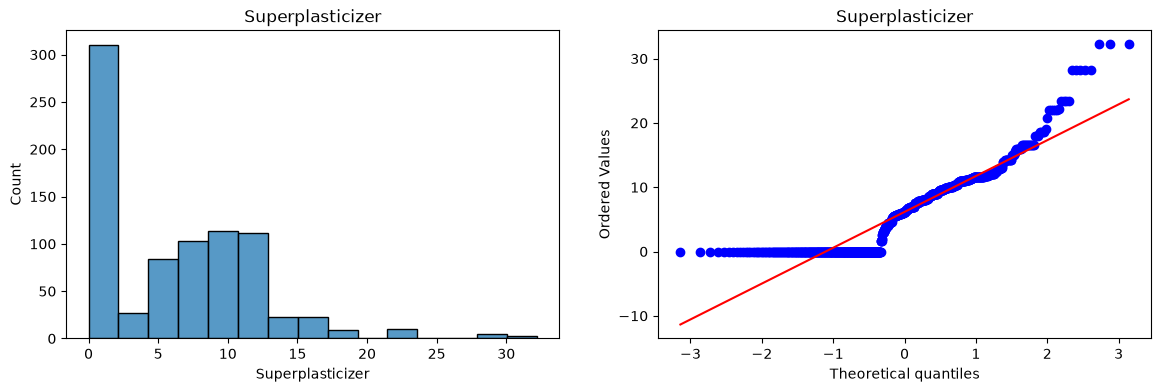

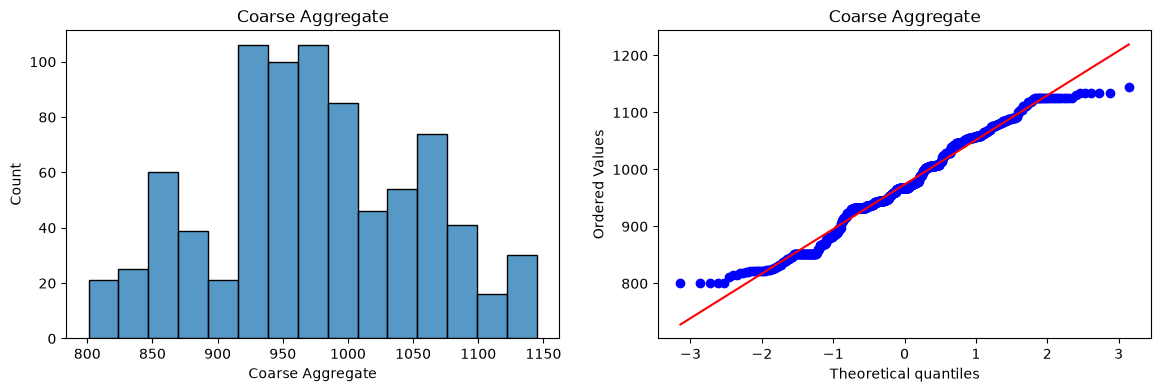

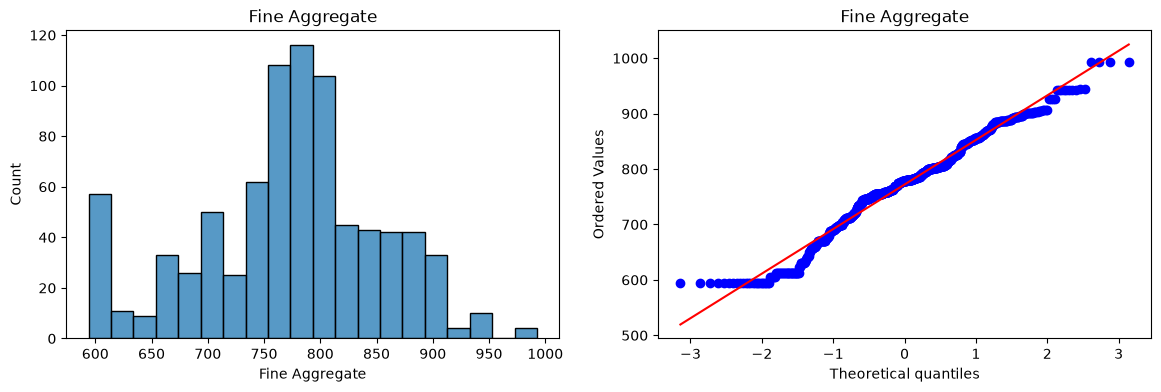

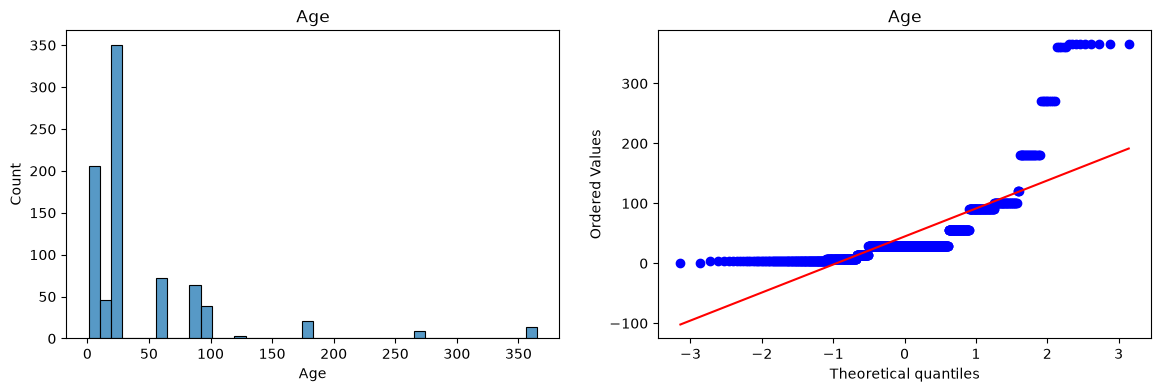

In [35]:
# plotting the distplots without any transformation

for col in X_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col])
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()

In [38]:
# applying box-cox transform

pt = PowerTransformer(method='box-cox')

# as box-cox is restricted to use data with 0 or -ve we add 0.000001
X_train_transformed = pt.fit_transform(X_train+0.000001)
X_test_transformed = pt.fit_transform(X_test+0.000001)

# Create a DataFrame showing each feature and the lambda value found by Box-Cox
pd.DataFrame({
    'cols': X_train.columns,              # Get the names of all columns
    'box_cox_lambdas': pt.lambdas_        # Get the Box-Cox lambda for each column
})
#pt.lambdas_ is therefore an array containing the lambda found for each column.

,cols,box_cox_lambdas
0,Cement,0.215602
1,Blast Furnace Slag,0.025996
2,Fly Ash,-0.006544
3,Water,0.959062
4,Superplasticizer,0.103365
5,Coarse Aggregate,1.192492
6,Fine Aggregate,1.973781
7,Age,-0.014692


##### For example, if Cement has a value 540, Box-Cox uses Cement's λ 0.2156 to transform 540.Every other Cement value also uses 0.2156, because λ is chosen for the whole column.Each column has its own λ, which is why Water uses 0.9591, Age uses -0.0147, etc.

In [39]:
# applying linear regression on transfomed data

lr = LinearRegression()
lr.fit(X_train_transformed, y_train)

y_pred2 = lr.predict(X_test_transformed)

r2_score(y_test, y_pred2)

0.8055321004852343

In [42]:
# using cross value score

pt = PowerTransformer(method = 'box-cox')
X_transformed = pt.fit_transform(X+0.000001)

lr = LinearRegression()
np.mean(cross_val_score(lr, X_transformed, y, scoring='r2'))

np.float64(0.6662950319246963)

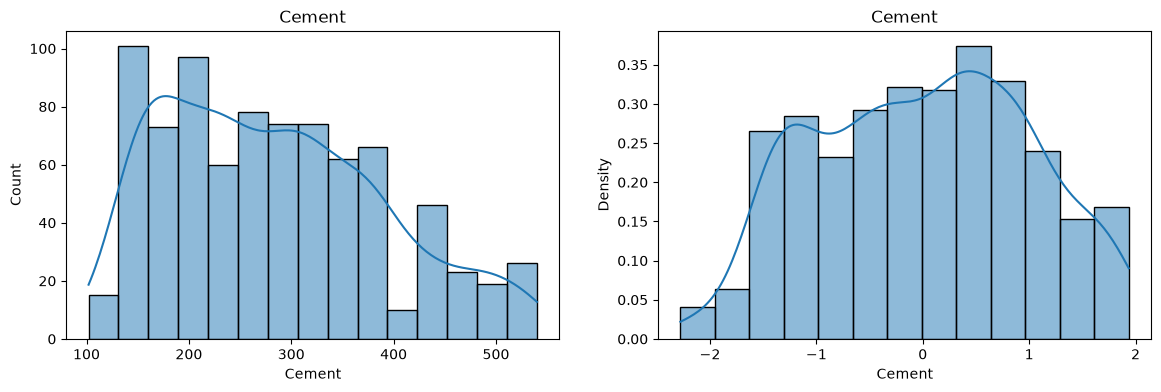

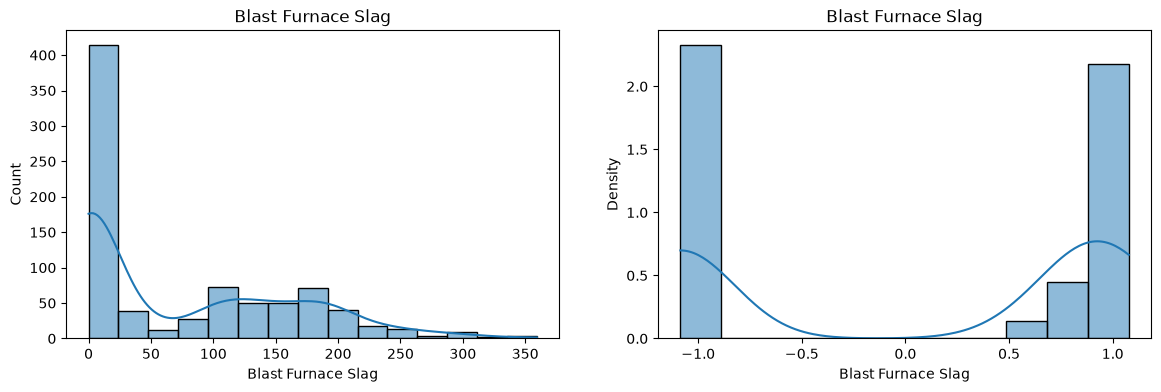

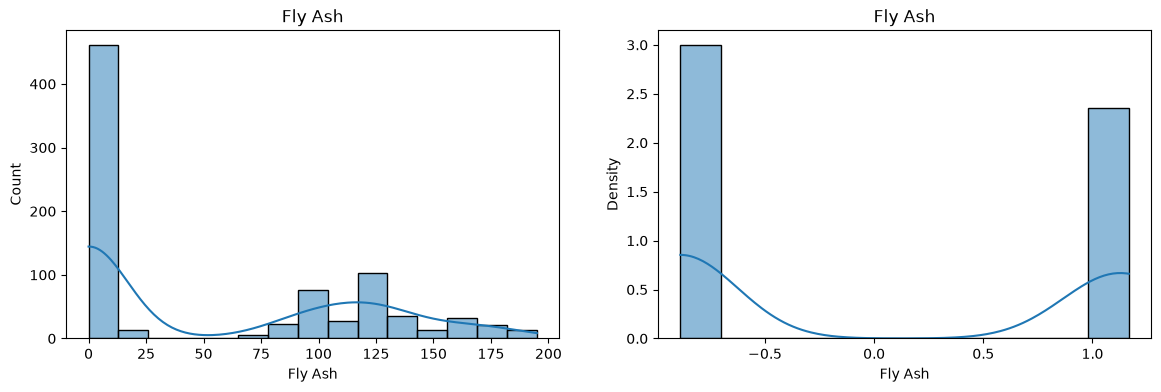

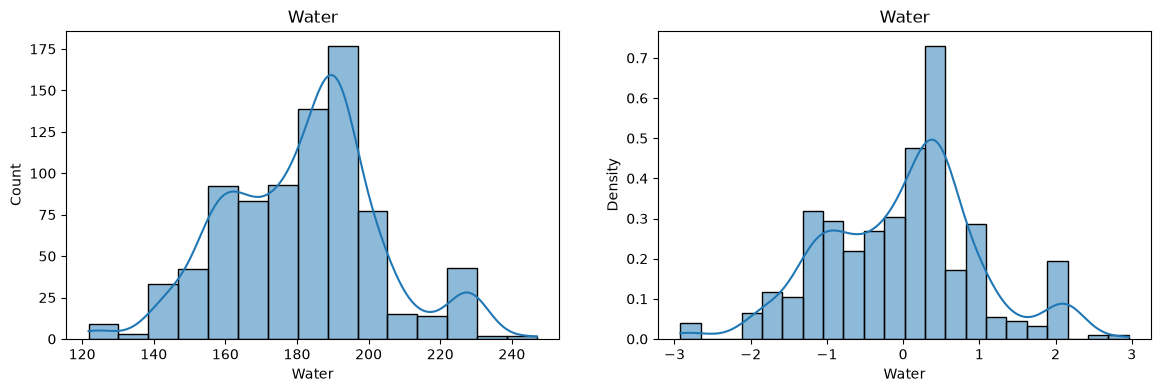

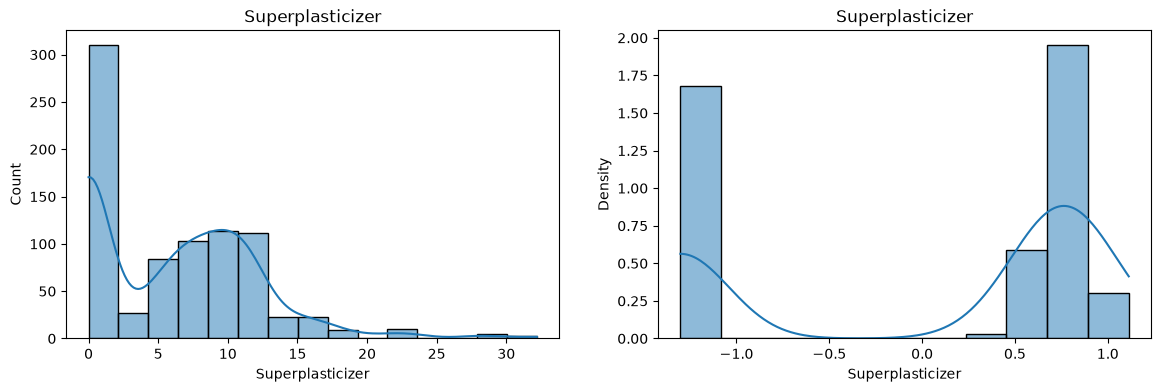

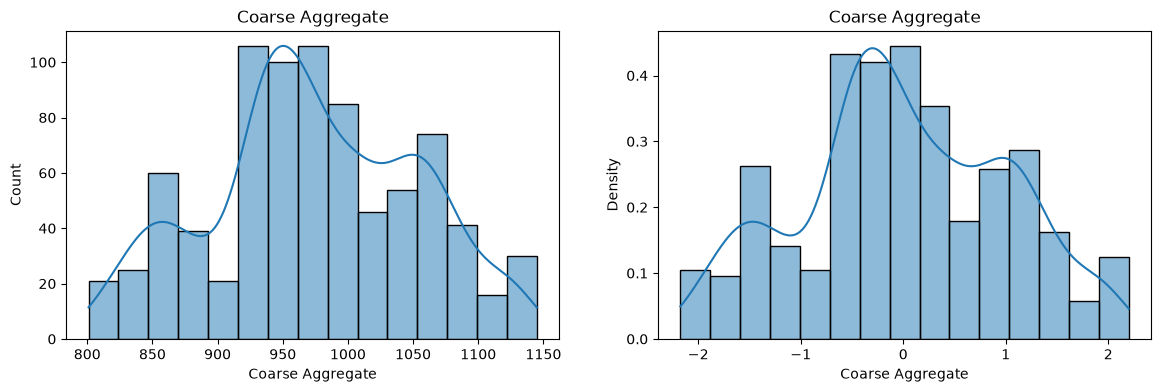

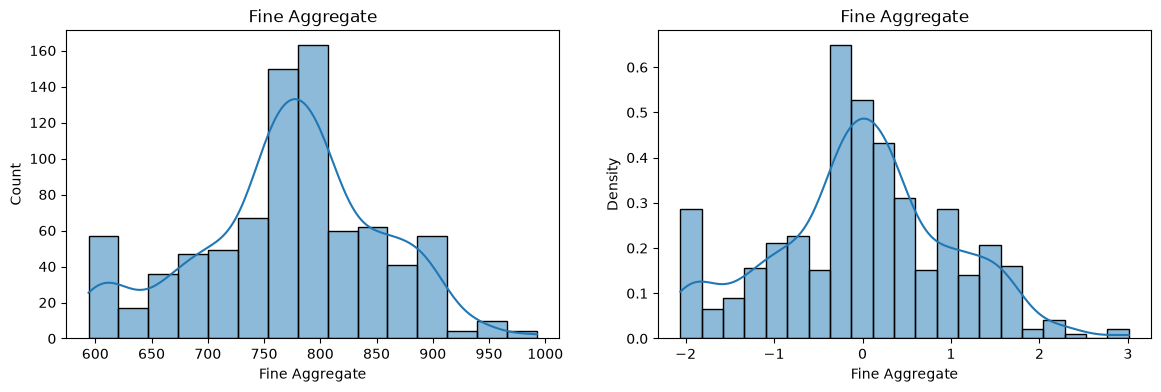

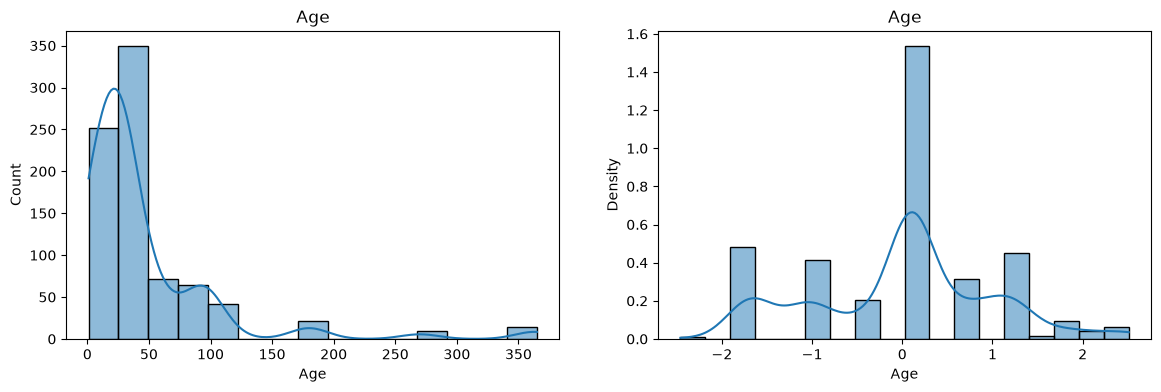

In [53]:
# before and after comparision for box-cox plot

#basically converts your transformed NumPy array back into a DataFrame and gives the columns their original names.
X_train_transformed = pd.DataFrame(X_train_transformed, columns=X_train.columns)

for col in X_train_transformed.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True, bins=15)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(X_train_transformed[col], kde=True, stat="density")
    plt.title(col)

    plt.show()

In [71]:
# APPLY YEO-JOHNSON TRANSFORM

pt1 = PowerTransformer() # no need to pass method=yeo-johnson because it is by defualt yeo-johnson transformer

X_train_transformed2 = pt1.fit_transform(X_train)
X_test_transformed2 = pt1.fit_transform(X_test)

lr = LinearRegression()
lr.fit(X_train_transformed, y_train)

y_pred3 = lr.predict(X_test_transformed2)

# Create a DataFrame showing each feature and the lambda value found by YEO-JOHNSON
pd.DataFrame({'cols': X_train.columns,
              'Yeo_Johnson_lambdas' : pt1.lambdas_})
#pt.lambdas_ is therefore an array containing the lambda found for each column.

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,cols,Yeo_Johnson_lambdas
0,Cement,0.213025
1,Blast Furnace Slag,0.020476
2,Fly Ash,-0.038218
3,Water,0.958936
4,Superplasticizer,0.304951
5,Coarse Aggregate,1.192751
6,Fine Aggregate,1.975085
7,Age,-0.062443


In [61]:
r2_score(y_test, y_pred3)

0.8001287403672925

In [64]:
# applying cross val score

pt = PowerTransformer() # by default yeo-johnson
X_transformer2 = pt.fit_transform(X)

lr = LinearRegression()
np.mean(cross_val_score(lr, X_transformer2, y, scoring = 'r2'))

np.float64(0.6834625160224895)

In [66]:
X_train_transformed2 = pd.DataFrame(X_train_transformed2,
                                  columns= X_train.columns)

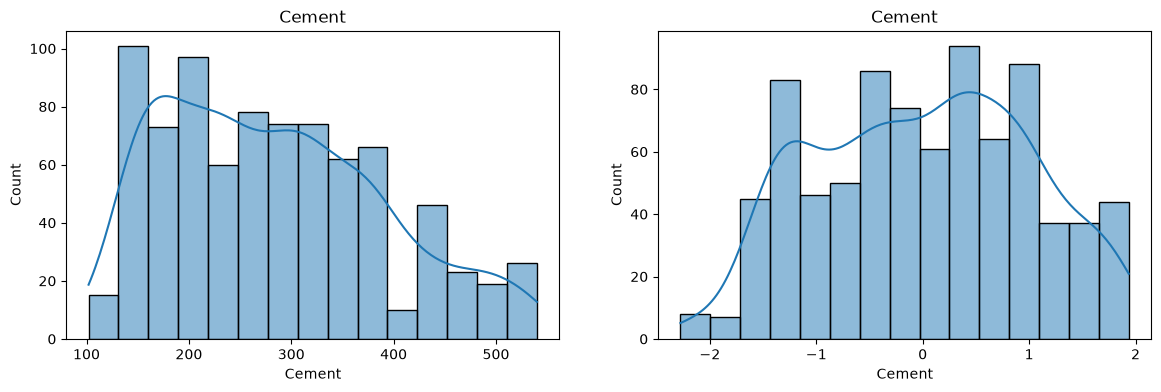

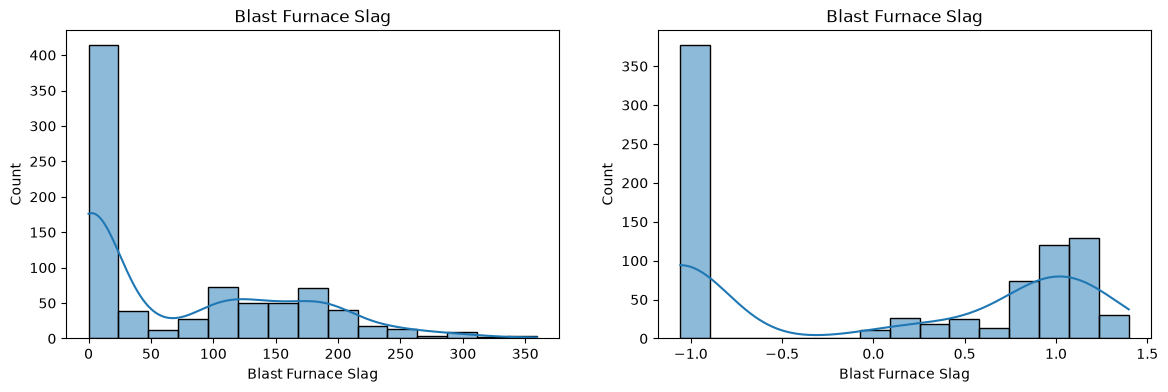

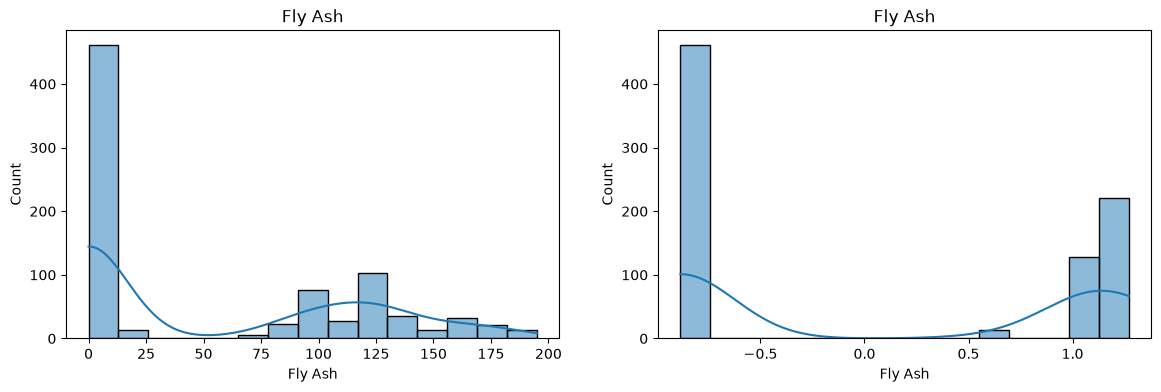

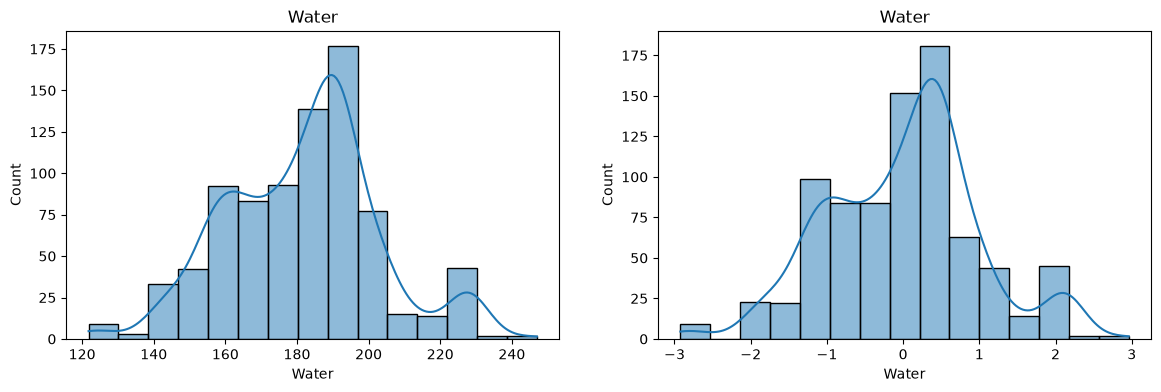

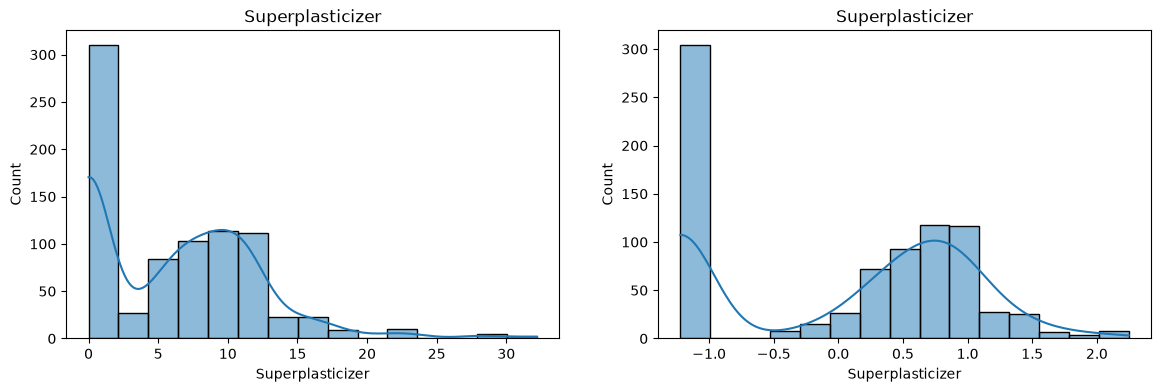

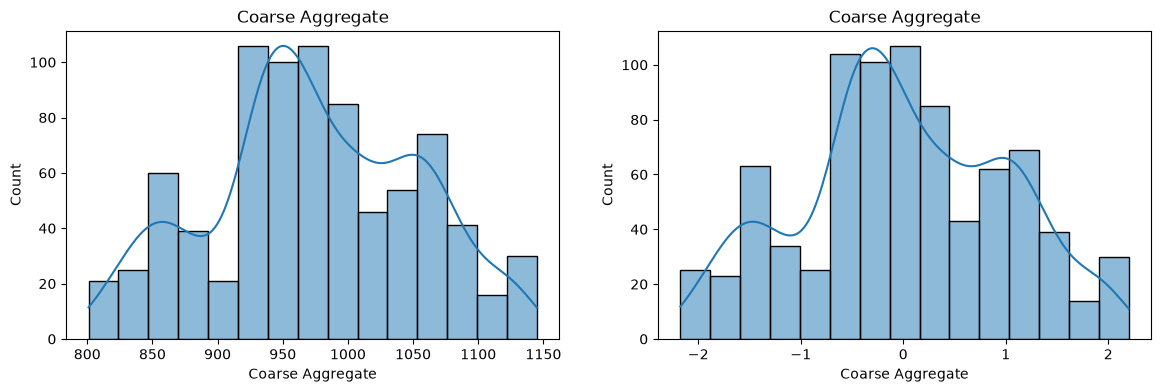

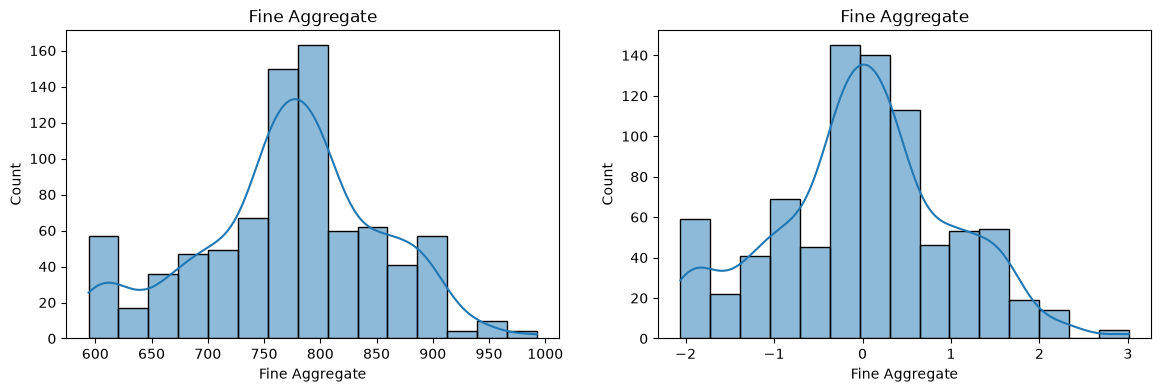

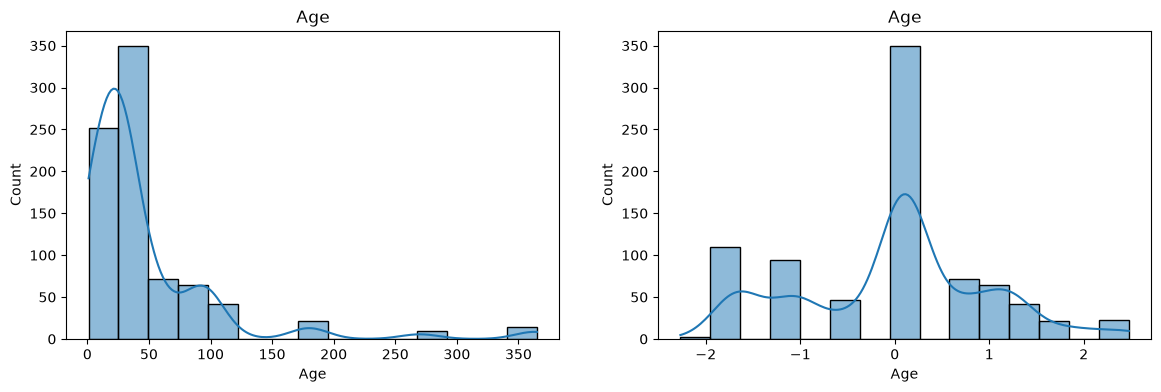

In [69]:
# b4 and after comparision for Yeo-Johnson

for col in X_train_transformed2.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True, bins=15)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(X_train_transformed2[col], kde=True, bins=15)
    plt.title(col)

    plt.show()

In [70]:
# SIDE BY SIDE LAMBDAS COMPARISON

pd.DataFrame({'cols': X_train.columns,
              'box_cox_lambdas': pt.lambdas_,
             'Yeo_Johnson_lambdas': pt1.lambdas_})

,cols,box_cox_lambdas,Yeo_Johnson_lambdas
0,Cement,0.169544,0.213025
1,Blast Furnace Slag,0.016633,0.020476
2,Fly Ash,-0.136480,-0.038218
3,Water,0.808438,0.958936
4,Superplasticizer,0.264160,0.304951
5,Coarse Aggregate,1.129395,1.192751
6,Fine Aggregate,1.830764,1.975085
7,Age,0.001771,-0.062443
